# Results & Model Comparison

Dataset: `dair-ai/emotion`, balanced to 10,000 rows per label (60,000 total), stratified 80/20 split (48,000 train / 12,000 test).

| Rank | Model | Features / Architecture | Test Accuracy | Macro F1 |
|:----:|-------|-------------------------|:-------------:|:--------:|
| **1** | **BERT (`bert-base-uncased`)** | **Fine-tuned transformer** | **95.1%** | **0.950** |
| 2 | Bidirectional LSTM | Trainable embeddings + stacked BiLSTM | 94.2% | - |
| 3 | Logistic Regression (Optuna-tuned) | TF-IDF (unigrams + bigrams) | 91.2% | - |
| 4 | XGBoost | TF-IDF (unigrams + bigrams) | 91.1% | 0.910 |
| 5 | Logistic Regression (baseline) | TF-IDF (unigrams + bigrams) | 90.2% | 0.902 |

## Key Takeaways

- **BERT performed best at 95.1%**, about 3.9 points above the tuned Logistic Regression and 0.9 points above the BiLSTM.
- **Classical models are strong baselines.** TF-IDF with Logistic Regression and XGBoost already reaches about 91%, and trains quickly. Optuna tuning gave Logistic Regression a gain of about 1 point (90.2% to 91.2%).
- **Deep learning models gain from context.** The BiLSTM and BERT read the whole sentence in order, so they handle word order and negation better than bag-of-words features.
- **The gap between BiLSTM and BERT is small (0.9 points).** BERT's advantage comes from pretraining on large text corpora, at the cost of a much larger model and longer training.


The fine-tuned BERT model is available on the Hugging Face Hub: [`Deepakathf/bert-emotion-finetuned`](https://huggingface.co/Deepakathf/bert-emotion-finetuned)

# Importing Libraries

In [33]:
# for data handling
import numpy as np
import pandas as pd

# for visualization
import seaborn as sns
import matplotlib.pyplot as plt

# text processing libraries
import re
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

# Models
import optuna
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import CountVectorizer,TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split,cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,f1_score,confusion_matrix,classification_report
from xgboost import XGBClassifier

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input,Embedding, LSTM, Dense, Dropout,Bidirectional
from tensorflow.keras.preprocessing import sequence
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau


from collections import Counter
# Tokenize and pad sequences
from tensorflow.keras.preprocessing.text import Tokenizer

from datasets import load_dataset,DatasetDict,Dataset

import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_colwidth',None)
seed=42

# EDA

In [34]:
# data importing from hugging face
df = load_dataset("dair-ai/emotion", "unsplit")["train"].to_pandas()

In [35]:
df

,text,label
0,i feel awful about it too because it s my job to get him in a position to succeed and it just didn t happen here,0
1,im alone i feel awful,0
2,ive probably mentioned this before but i really do feel proud of myself for actually keeping up with my new years resolution of monthly and weekly goals,1
3,i was feeling a little low few days back,0
4,i beleive that i am much more sensitive to other peoples feelings and tend to be more compassionate,2
...,...,...
416804,that was what i felt when i was finally accepted in the bulgarian conservatorie after i had applied a couple of years,1
416805,i take every day as it comes i m just focussing on eating better at the moment i m not aiming for unrealistic targets or setting myself deadlines because then i feel pressured i m just improving my diet,4
416806,i just suddenly feel that everything was fake,0
416807,im feeling more eager than ever to claw back what went pear shaped last week and get back on track,1


In [36]:
new=load_dataset("dair-ai/emotion", "unsplit")
new['train'].features['label'].names

['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']

In [37]:
names = new['train'].features['label'].names  # ['sadness','joy','love','anger','fear','surprise']
id_to_label={i:label for i,label in enumerate(names)}
print(id_to_label)
df["label_name"] = df["label"].map(id_to_label)

{0: 'sadness', 1: 'joy', 2: 'love', 3: 'anger', 4: 'fear', 5: 'surprise'}


In [38]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 416809 entries, 0 to 416808
Data columns (total 3 columns):
 #   Column      Non-Null Count   Dtype 
---  ------      --------------   ----- 
 0   text        416809 non-null  object
 1   label       416809 non-null  int64 
 2   label_name  416809 non-null  object
dtypes: int64(1), object(2)
memory usage: 9.5+ MB


### Selecting each 10k rows of each label

In [39]:
df = df.groupby("label").sample(n=10000, random_state=seed)  # 60k rows

In [40]:
df.shape

(60000, 3)

In [41]:
df.label_name.value_counts(normalize=True)

label_name
sadness     0.166667
joy         0.166667
love        0.166667
anger       0.166667
fear        0.166667
surprise    0.166667
Name: proportion, dtype: float64

In [42]:
for i in df.label_name.unique():
    print(i,df[df.label_name==i].shape[0])

sadness 10000
joy 10000
love 10000
anger 10000
fear 10000
surprise 10000


## Plotting 15 most common words of each label 

In [43]:
# first removing stopwords
nltk.download('stopwords')
nltk.download('punkt_tab')
nltk.download('wordnet')
STOPWORDS=set(stopwords.words('english'))
STOPWORDS |= {"feel", "feeling", "feels", "felt", "like", "im", "ive",
              "get", "would", "one", "really", "know", "little", "going","time"}
from wordcloud import WordCloud

[nltk_data] Downloading package stopwords to /usr/share/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt_tab to /usr/share/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package wordnet to /usr/share/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


Most common words for sadness : [('still', 416), ('people', 392), ('think', 380), ('life', 379), ('even', 367), ('want', 339), ('dont', 335), ('bit', 330), ('much', 319), ('something', 287), ('way', 284), ('could', 284), ('things', 284), ('make', 264), ('go', 261)]


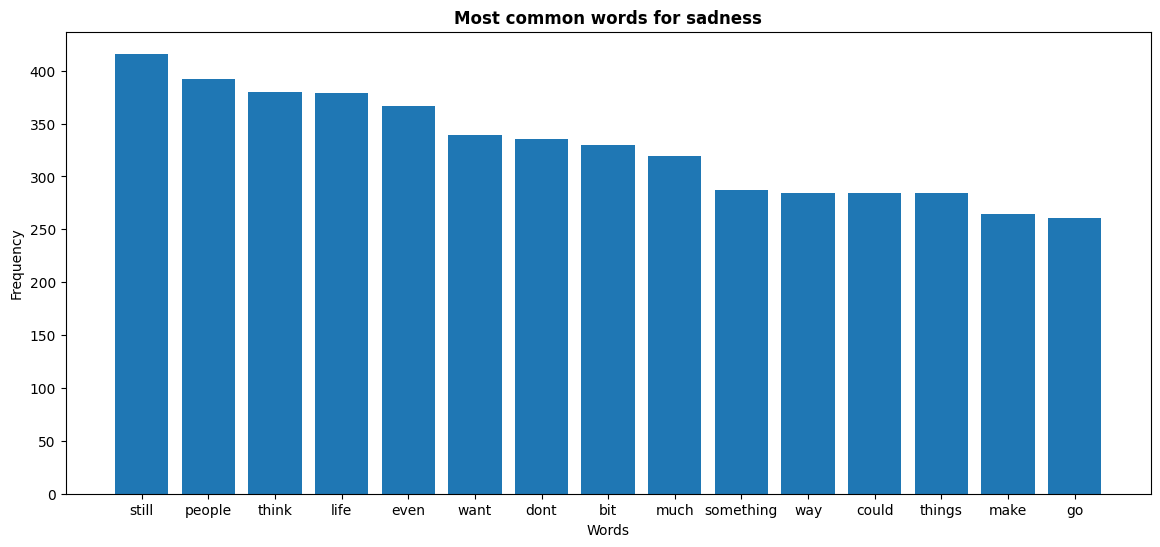

Most common words for joy : [('want', 431), ('people', 430), ('think', 395), ('life', 371), ('much', 369), ('love', 367), ('make', 355), ('something', 346), ('good', 338), ('pretty', 337), ('still', 330), ('things', 330), ('way', 321), ('day', 311), ('even', 302)]


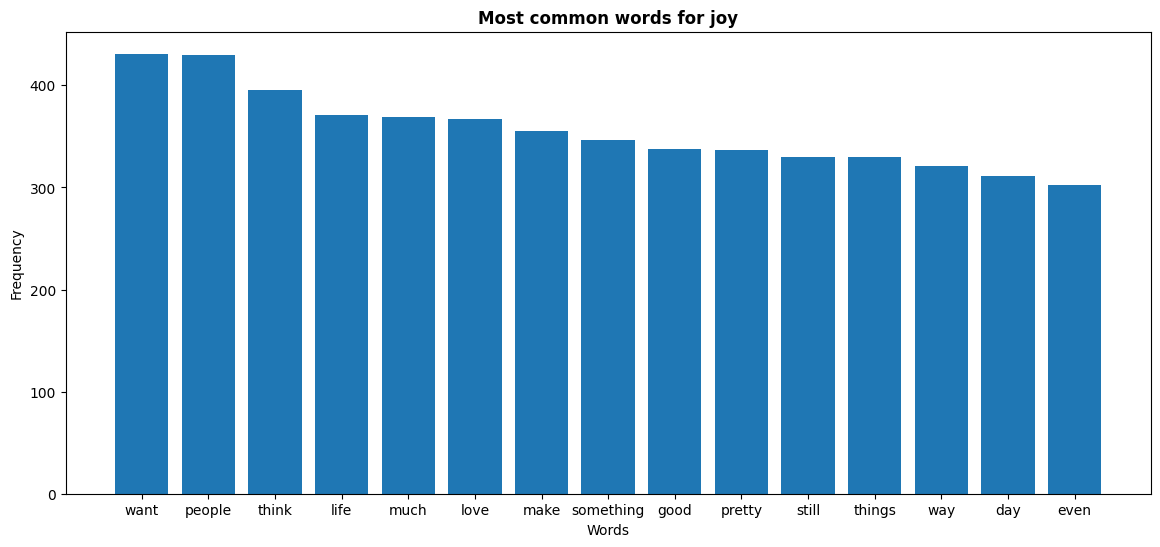

Most common words for love : [('love', 715), ('loved', 509), ('loving', 467), ('people', 464), ('liked', 458), ('want', 456), ('hot', 455), ('caring', 435), ('sweet', 432), ('longing', 427), ('much', 421), ('gentle', 409), ('tender', 407), ('sympathetic', 399), ('accepted', 393)]


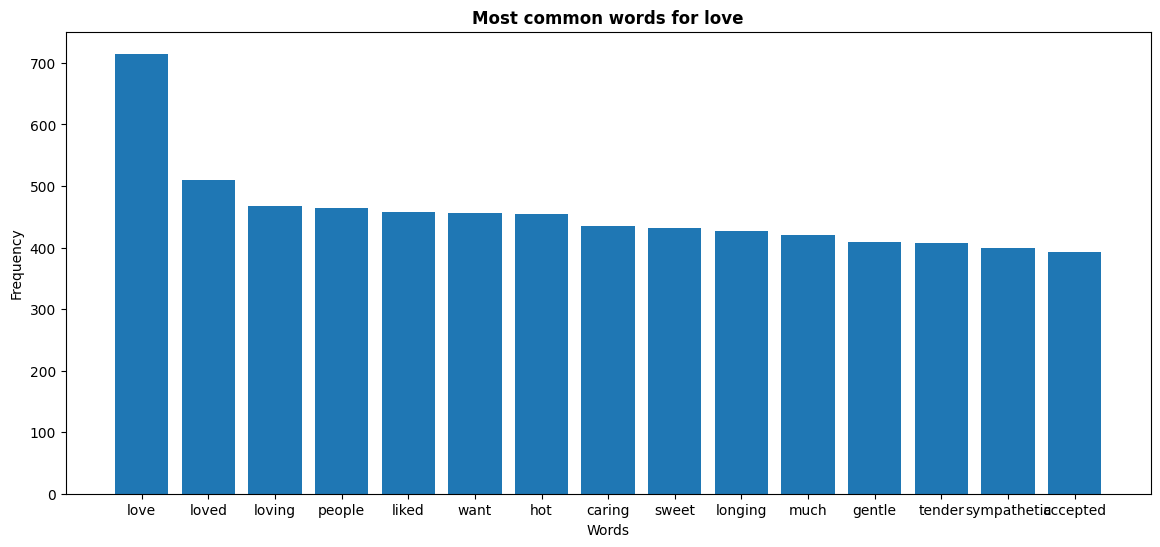

Most common words for anger : [('people', 595), ('want', 472), ('think', 426), ('angry', 425), ('dont', 403), ('even', 383), ('things', 366), ('something', 356), ('bit', 345), ('still', 324), ('way', 318), ('much', 313), ('frustrated', 305), ('selfish', 292), ('could', 290)]


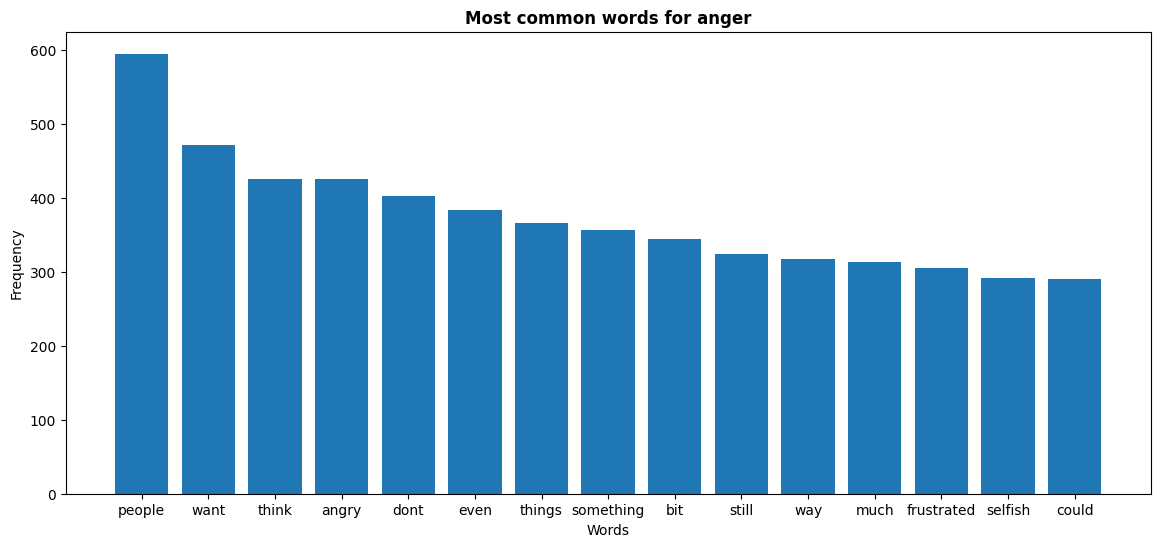

Most common words for fear : [('bit', 521), ('still', 511), ('people', 418), ('think', 396), ('scared', 390), ('afraid', 385), ('anxious', 358), ('want', 356), ('even', 351), ('nervous', 340), ('things', 332), ('insecure', 331), ('dont', 330), ('something', 322), ('strange', 317)]


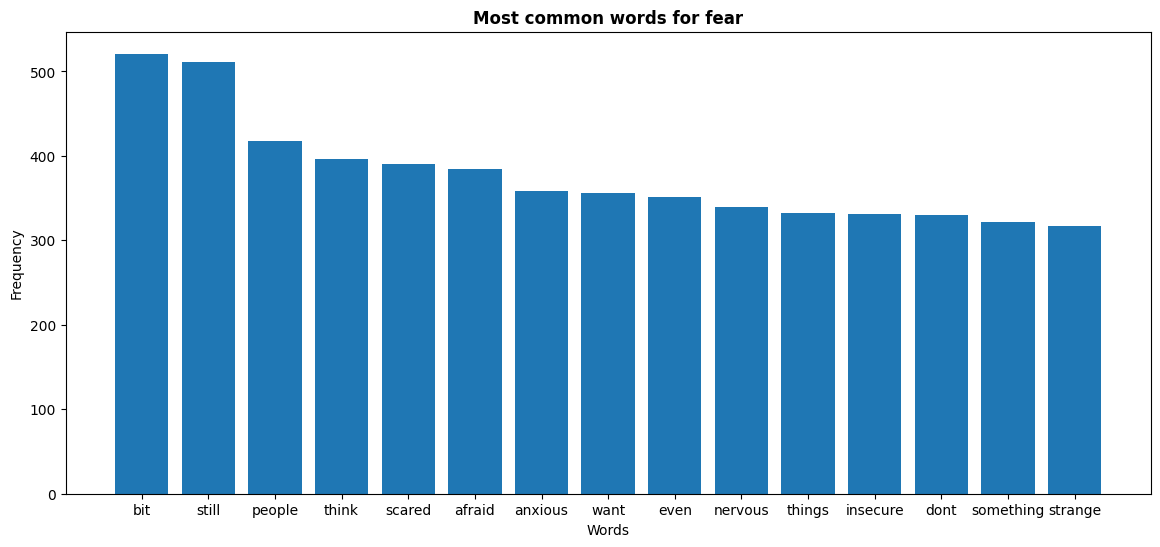

Most common words for surprise : [('weird', 963), ('impressed', 962), ('strange', 946), ('overwhelmed', 945), ('amazed', 929), ('surprised', 906), ('shocked', 900), ('amazing', 895), ('funny', 881), ('curious', 855), ('dazed', 596), ('still', 551), ('bit', 471), ('people', 463), ('stunned', 436)]


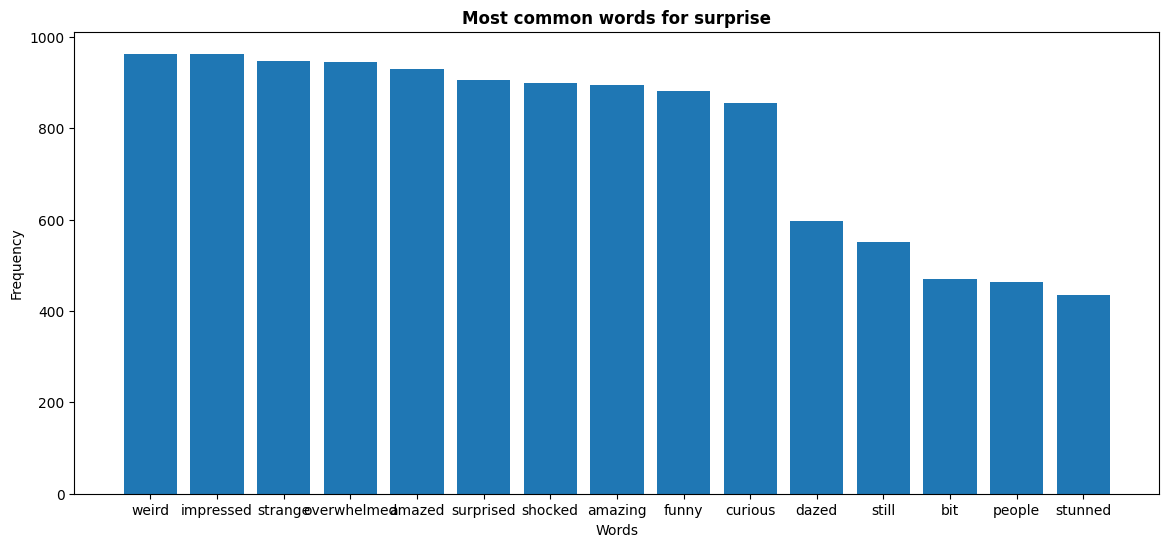

In [15]:
def get_word_freq(status):
    sentence=' '.join(df[df.label_name==status]['text'])
    words=word_tokenize(sentence.lower())
    words_filtered=[word for word in words if word.isalpha() and word not in STOPWORDS]
    word_freq=Counter(words_filtered)
    return word_freq

for status in df.label_name.unique():
    word_freq=get_word_freq(status)
    most_common_words=word_freq.most_common(15)
    print(f'Most common words for {status} : {most_common_words}')
    
    word,count=zip(*most_common_words)
    plt.figure(figsize=(14,6))
    plt.bar(word,count)
    plt.xlabel('Words')
    plt.ylabel('Frequency')
    plt.title(f'Most common words for {status}',fontweight='bold')
    plt.show()

## WordCloud

In [16]:
def word_clouds(status):
    sentence=' '.join(df[df.label_name==status]['text'])
    words=word_tokenize(sentence.lower())
    words_filtered=[word for word in words if word.isalpha() and word not in STOPWORDS]
    sentence=' '.join(words_filtered)
    wordcloud=WordCloud(background_color='black',width=900,height=500).generate(sentence)
    plt.figure(figsize=(18,6))
    plt.imshow(wordcloud,interpolation='bilinear')
    plt.axis('off')
    plt.title(f'Word Cloud for {status}')
    plt.show()

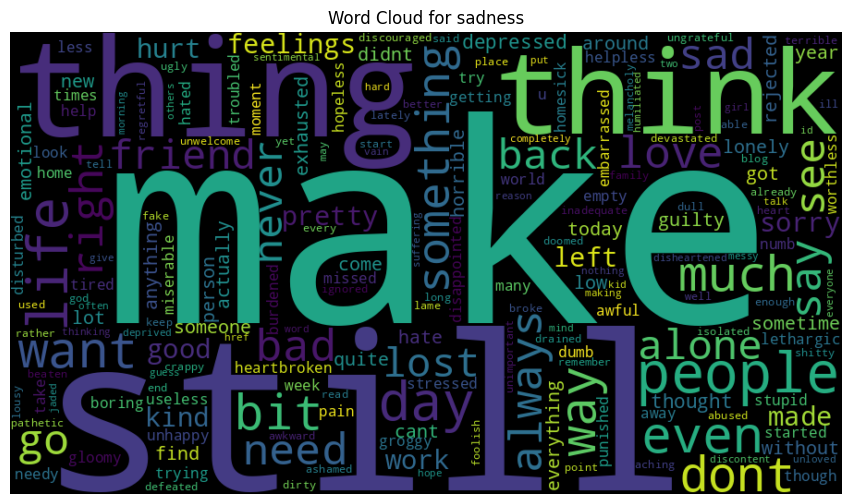

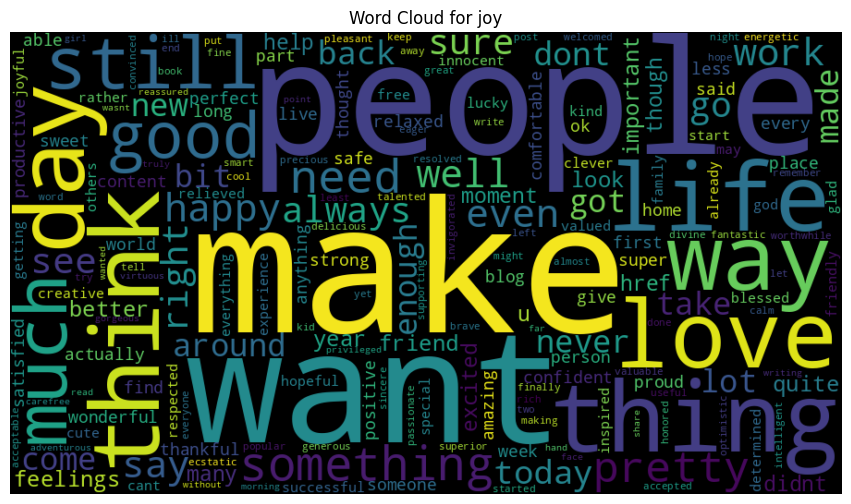

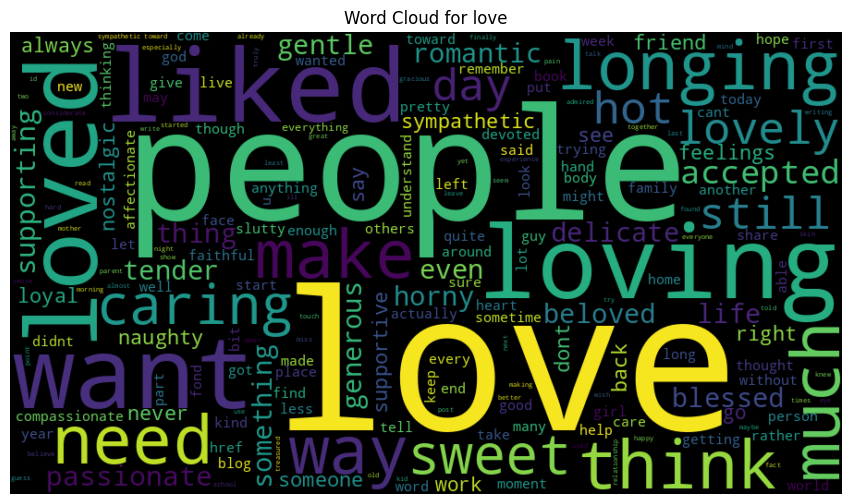

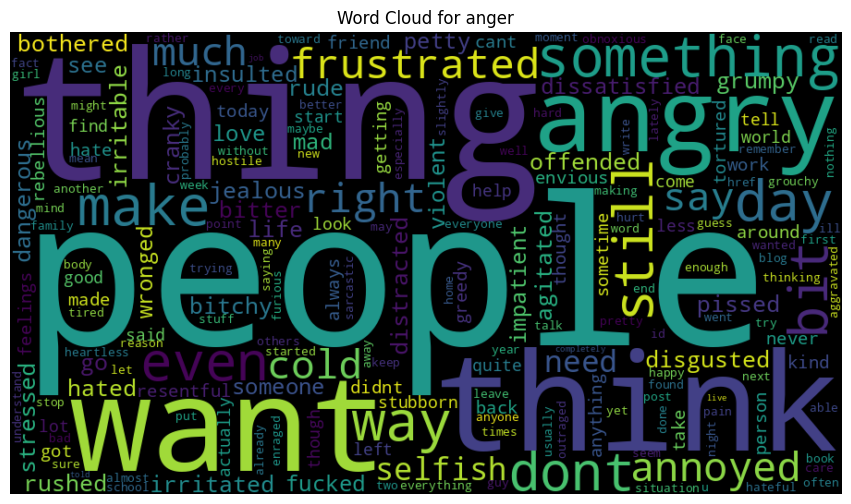

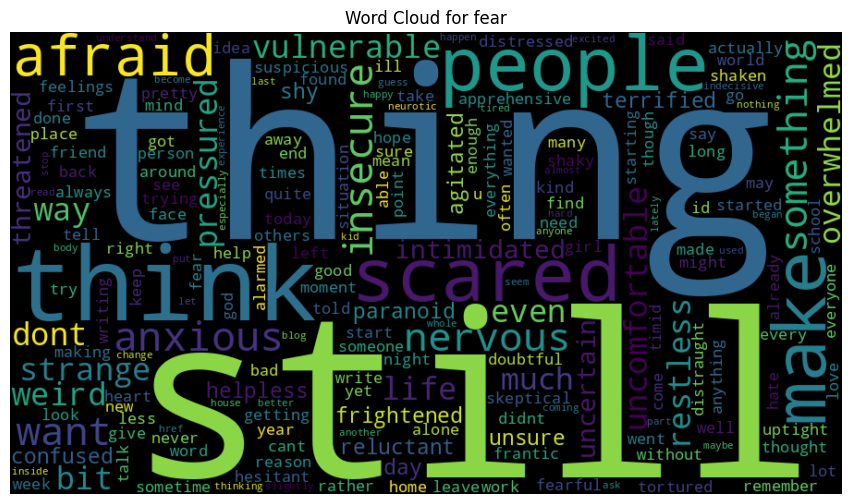

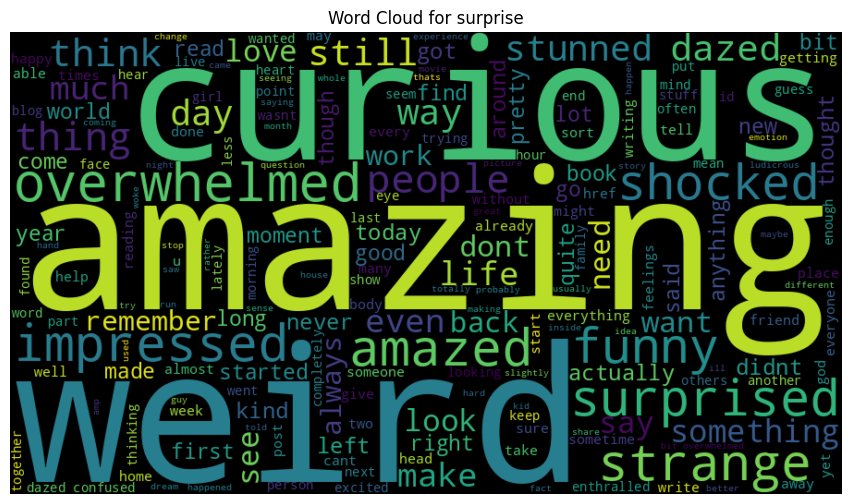

In [17]:
for status in df.label_name.unique():
    word_clouds(status)

# Model Training

In [44]:
# Splitting the data
X=df['text']
y=df['label']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=seed,stratify=y)
print(f'{X_train.shape[0]} rows')
print(f'{X_test.shape[0]} rows')

48000 rows
12000 rows


## Logistic Regression with tf-idf vectorizer

Accuracy with Logistic Regression : 0.902
Macro F1 with Logistic Regression : 0.902
Classification Report for Logistic Regression model
              precision    recall  f1-score   support

           0       0.94      0.90      0.92      2000
           1       0.90      0.87      0.88      2000
           2       0.90      0.93      0.91      2000
           3       0.93      0.92      0.93      2000
           4       0.87      0.85      0.86      2000
           5       0.89      0.93      0.91      2000

    accuracy                           0.90     12000
   macro avg       0.90      0.90      0.90     12000
weighted avg       0.90      0.90      0.90     12000

Confusion Matrix for Logistic Regression


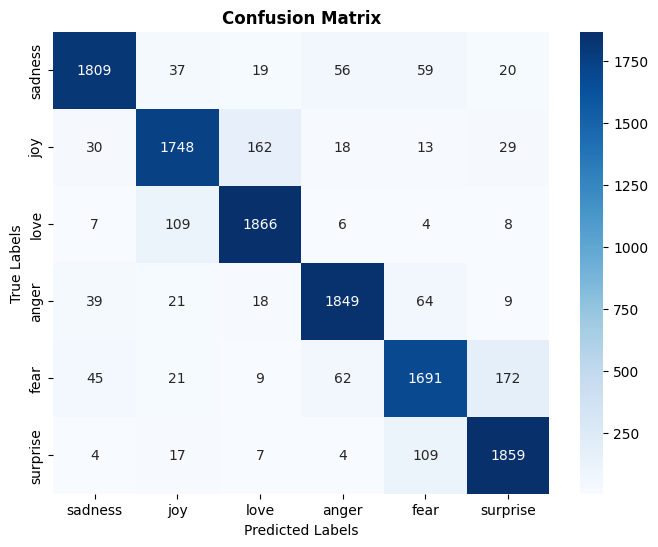

In [19]:
vectorizer = TfidfVectorizer(max_df=0.7, max_features=10000, ngram_range=(1,2),sublinear_tf=True)
X_train_vec=vectorizer.fit_transform(X_train)
X_test_vec=vectorizer.transform(X_test)
lr=LogisticRegression(max_iter=1000,C=5,random_state=seed)
lr.fit(X_train_vec, y_train)

y_pred = lr.predict(X_test_vec)
print(f'Accuracy with Logistic Regression : {accuracy_score(y_test, y_pred):.3f}')
print(f'Macro F1 with Logistic Regression : {f1_score(y_test, y_pred, average='macro'):.3f}')
print('Classification Report for Logistic Regression model')
print(classification_report(y_test, y_pred))

print('Confusion Matrix for Logistic Regression')
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, cmap='Blues', fmt='d', xticklabels=names, yticklabels=names)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix',fontweight='bold')
plt.show()

## Hyperparamter Tuning with Optuna

In [26]:
def objective(trial):
    # tf_idf hyperparameters
    max_ngram    = trial.suggest_int('max_ngram', 1, 2)
    min_df       = trial.suggest_int('min_df', 1, 5)
    max_df       = trial.suggest_float('max_df', 0.8, 1.0, step=0.05)
    max_features = trial.suggest_categorical('max_features', [20000, 50000, None])
    sublinear_tf = trial.suggest_categorical('sublinear_tf', [True, False])

    # Log regression hyperparameter
    C = trial.suggest_float('C', 0.1, 100, log=True)

    # creating model
    model = make_pipeline(
        TfidfVectorizer(
            ngram_range=(1, max_ngram),
            min_df=min_df,
            max_df=max_df,
            max_features=max_features,
            sublinear_tf=sublinear_tf,
        ),
        LogisticRegression(C=C, max_iter=1000, random_state=42),
    )

    score = cross_val_score(model, X_train, y_train, cv=3, scoring='accuracy', n_jobs=-1).mean()
    return score



In [27]:
# study object 
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=30)

[I 2026-11-04 11:43:51,266] A new study created in memory with name: no-name-a0a7dac8-a3ae-42d3-86b1-10f9df2fa72e
[I 2026-11-04 11:43:56,807] Trial 0 finished with value: 0.8997083333333333 and parameters: {'max_ngram': 1, 'min_df': 5, 'max_df': 0.9500000000000001, 'max_features': 20000, 'sublinear_tf': False, 'C': 6.358358856676251}. Best is trial 0 with value: 0.8997083333333333.
[I 2026-11-04 11:44:05,242] Trial 1 finished with value: 0.9053749999999999 and parameters: {'max_ngram': 2, 'min_df': 1, 'max_df': 1.0, 'max_features': 20000, 'sublinear_tf': False, 'C': 3.752055855124281}. Best is trial 1 with value: 0.9053749999999999.
[I 2026-11-04 11:44:08,429] Trial 2 finished with value: 0.9024375 and parameters: {'max_ngram': 1, 'min_df': 2, 'max_df': 0.9500000000000001, 'max_features': None, 'sublinear_tf': False, 'C': 0.3972110727381912}. Best is trial 1 with value: 0.9053749999999999.
[I 2026-11-04 11:44:17,439] Trial 3 finished with value: 0.8958541666666666 and parameters: {'max

In [30]:
#print(study.best_value, study.best_params)
print(f'Study best value: {study.best_value}')
print(f'Best parameters : {study.best_params}')

Study best value: 0.908
Best parameters : {'max_ngram': 2, 'min_df': 5, 'max_df': 0.8500000000000001, 'max_features': None, 'sublinear_tf': False, 'C': 1.2569598473527563}


In [35]:
# Training with best parameters
best = study.best_params

final_log_r_model = make_pipeline(
    TfidfVectorizer(
        ngram_range=(1, best['max_ngram']),
        min_df=best['min_df'],
        max_df=best['max_df'],
        max_features=best['max_features'],
        sublinear_tf=best['sublinear_tf'],
    ),
    LogisticRegression(C=best['C'], max_iter=1000, random_state=42),
)
final_log_r_model.fit(X_train, y_train)
print(f'Final Logistic Regression accuracy with Optuna is : {final_log_r_model.score(X_test, y_test):.3f}')

Final Logistic Regression accuracy with Optuna is : 0.912


In [33]:
from optuna.visualization import plot_param_importances
plot_param_importances(study).show()

### `C` and `max_df` value has more importances than rest of other parameters

## TF-IDF Vectorizer

In [20]:
def tfidf_vec_boost(model,max_features, ngram_range, n_estimators,min_df=5,max_df=0.7, max_depth=3, learning_rate=0.07):

    vectorizer = TfidfVectorizer(max_df=max_df, max_features=max_features, ngram_range=ngram_range,sublinear_tf=True)
    X_train_vector = vectorizer.fit_transform(X_train)
    classifier = model(n_estimators=n_estimators, max_depth=max_depth, learning_rate=learning_rate,verbose=False)
    classifier.fit(X_train_vector, y_train)
    X_test_vector = vectorizer.transform(X_test)
    y_pred = classifier.predict(X_test_vector)
    print(f'Macro F1 score using {model}:{f1_score(y_test, y_pred, average="macro")}')
    print(f'Accuracy using {model}: {accuracy_score(y_test,y_pred)}')
    print(classification_report(y_test, y_pred))

    #Plotting classification report
    cm = confusion_matrix(y_test, y_pred)
    class_labels = y.unique().tolist()
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, cmap='Reds', fmt='d', xticklabels=names, yticklabels=names)
    plt.xlabel('Predicted Labels')
    plt.ylabel('True Labels')
    plt.title('Confusion Matrix',fontweight='bold')
    plt.show()

### Using XGBoost Classifier

Macro F1 score using <class 'xgboost.sklearn.XGBClassifier'>:0.9104022057922174
Accuracy using <class 'xgboost.sklearn.XGBClassifier'>: 0.9108333333333334
              precision    recall  f1-score   support

           0       0.97      0.87      0.92      2000
           1       0.88      0.87      0.88      2000
           2       0.89      0.97      0.93      2000
           3       0.94      0.90      0.92      2000
           4       0.91      0.87      0.89      2000
           5       0.88      0.99      0.93      2000

    accuracy                           0.91     12000
   macro avg       0.91      0.91      0.91     12000
weighted avg       0.91      0.91      0.91     12000



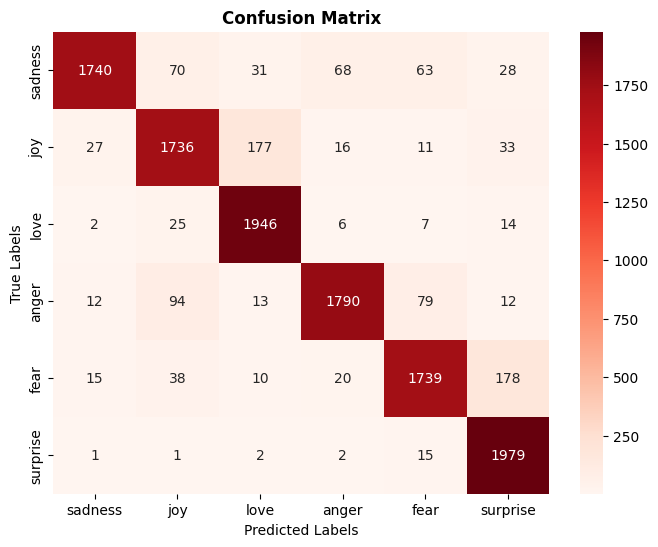

In [21]:
tfidf_vec_boost(model=XGBClassifier,n_estimators=700,ngram_range=(1,2),learning_rate=0.07,max_features=10000,max_df=0.7,max_depth=3)

## Bidirectional LSTM

In [ ]:
X=df['text']       #text column
y=df['label']      #label column

max_len = 64
vocab_size = 25000

# Tokenizing
tokenizer = Tokenizer(num_words=vocab_size, oov_token="<OOV>")
tokenizer.fit_on_texts(X)

# Sequence then pad_sequences
seqs = tokenizer.texts_to_sequences(X)
X_pad = sequence.pad_sequences(seqs, maxlen=max_len)

#Splitting the data into train:test into 80:20 ratio
X_train,X_test,y_train,y_test=train_test_split(X_pad,y,test_size=0.2,random_state=seed,stratify=y)
print(f'X_train size:{X_train.shape}')
print(f'X_test size:{X_test.shape}')


In [ ]:
# Creating model using keras' Sequential model with Embedding layers, Bidirectional, LSTM, Dense and dropout to avoid overfitting
model = Sequential()
model.add(Input(shape=(max_len,)))
model.add(Embedding(input_dim=vocab_size,output_dim=256))
model.add(Bidirectional(LSTM(64, dropout=0.3,return_sequences=True)))
model.add(Bidirectional(LSTM(64, dropout=0.2,return_sequences=True)))
model.add(Bidirectional(LSTM(32, dropout=0.3, recurrent_dropout=0.3)))
model.add(Dropout(0.3))
model.add(Dense(6,activation='softmax'))

#Compiling model
model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

#Final summary of the model
model.summary()

In [ ]:
# Using callbacks to monitor validation loss
callbacks=[
    EarlyStopping(monitor='val_loss',patience=3,restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss',factor=0.5,patience=3)
]

In [ ]:
history=model.fit(X_train, y_train, epochs=8, batch_size=64, validation_data = (X_test, y_test),callbacks=callbacks)
history

In [ ]:
y_pred=model.predict(X_test)
y_pred_prob=np.argmax(y_pred,axis=1)
print(classification_report(y_test,y_pred_prob))
print(f'Accuracy is {accuracy_score(y_test,y_pred_prob):.3f}')
print(f'Macro f1 score is {f1_score(y_test,y_pred_prob):.3f}')

In [ ]:
h=history.history
epochs=range(1,len(h['loss'])+1)
fig,ax=plt.subplots(1,2,figsize=(12,6))

ax[0].plot(epochs,h['accuracy'],'o-',label='train accuracy')
ax[0].plot(epochs,h['val_accuracy'],'o-',label='validation accuracy')
ax[0].set(title='Accuracy',xlabel='epochs',ylabel='Accuracy')
plt.legend()

ax[1].plot(epochs,h['loss'],'o-',label='train loss')
ax[1].plot(epochs,h['val_loss'],'o-',label='validation loss')
ax[1].set(title='Loss',xlabel='epochs',ylabel='loss')
plt.legend()
plt.tight_layout()
plt.show()

# BERT

In [45]:
train_df, test_df = train_test_split(df[["text", "label"]], test_size=0.2, random_state=seed, stratify=df["label"])

ds = DatasetDict({
    "train": Dataset.from_pandas(train_df.reset_index(drop=True)),
    "test":  Dataset.from_pandas(test_df.reset_index(drop=True)),
})
print(ds)

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 48000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 12000
    })
})


In [46]:
train_dataset=ds['train']
test_dataset=ds['test']

In [47]:
from transformers import Trainer, TrainingArguments
from transformers import (BertTokenizerFast, BertForSequenceClassification,
                          TrainingArguments, Trainer, set_seed)

In [48]:
id_to_label = {0:"sadness",1:"joy",2:"love",3:"anger",4:"fear",5:"surprise"}
label_to_id = {v:k for k,v in id_to_label.items()}

In [49]:
model_name='bert-base-uncased'
bert_tokenizer=BertTokenizerFast.from_pretrained(model_name)
bert_model=BertForSequenceClassification.from_pretrained(model_name,num_labels=6,id2label=id_to_label,label2id=label_to_id)
# Move model to GPU if available
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [50]:
# Tokenization function
def tokenize_func(examples):
    return bert_tokenizer(examples["text"], padding="max_length", truncation=True, max_length=64)

In [51]:
# Apply tokenization + rename + format 
def preprocess(ds):
    ds = ds.map(tokenize_func, batched=True, remove_columns=["text"])  # remove raw text (saves memory)
    ds = ds.rename_column("label", "labels")
    ds.set_format(type="torch", columns=["input_ids", "attention_mask", "labels"])
    return ds

In [52]:
train_dataset = preprocess(train_dataset)
test_dataset = preprocess(test_dataset)

Map:   0%|          | 0/48000 [00:00<?, ? examples/s]

Map:   0%|          | 0/12000 [00:00<?, ? examples/s]

In [54]:
def compute_metrics(p):
    logits=p.predictions.astype(np.float32)
    labels=p.label_ids
    preds=logits.argmax(axis=-1)
    return {
        'accuracy': accuracy_score(labels,preds),
        'macro_f1': f1_score(labels,preds,average='macro')
    }

In [55]:
# training arguments
training_args = TrainingArguments(
    output_dir="./results",
    num_train_epochs=6,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    learning_rate=2e-5,
    weight_decay=0.01,
    fp16=True,
    logging_steps=50,                  
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    seed=seed,
    report_to="none"
)

#trainer
trainer = Trainer(model=bert_model, args=training_args,
                  train_dataset=train_dataset,
                  eval_dataset=test_dataset,
                  compute_metrics=compute_metrics)
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.310212,0.306122,0.944167,0.943763
2,0.243505,0.256497,0.946583,0.945949
3,0.213465,0.256788,0.950500,0.950072
4,0.186818,0.275759,0.950000,0.949831
5,0.169717,0.290745,0.949250,0.949049
6,0.161505,0.307576,0.947250,0.947061


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

TrainOutput(global_step=4500, training_loss=0.29844753403133817, metrics={'train_runtime': 2072.8311, 'train_samples_per_second': 138.94, 'train_steps_per_second': 2.171, 'total_flos': 9472338173952000.0, 'train_loss': 0.29844753403133817, 'epoch': 6.0})

In [56]:
bert_model

BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e-12,

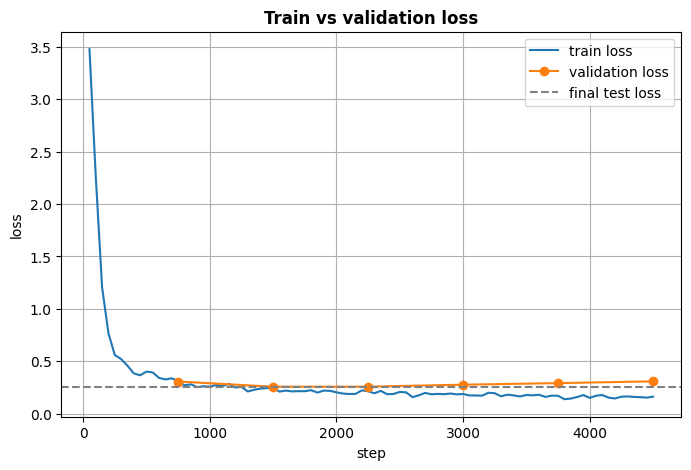

In [57]:
# plot for train and eval loss
log = trainer.state.log_history
tr_steps = [l["step"] for l in log if "loss" in l]
tr_loss  = [l["loss"] for l in log if "loss" in l]
ev_steps = [l["step"] for l in log if "eval_loss" in l]
ev_loss  = [l["eval_loss"] for l in log if "eval_loss" in l]

out = trainer.predict(test_dataset)                
plt.figure(figsize=(8, 5))
plt.plot(tr_steps, tr_loss, label="train loss")
plt.plot(ev_steps, ev_loss, "o-", label="validation loss")
plt.axhline(out.metrics["test_loss"], color="gray", ls="--", label="final test loss")
plt.xlabel("step")
plt.ylabel("loss")
plt.legend()
plt.grid()
plt.title("Train vs validation loss",fontweight='bold')
plt.show()

In [58]:
metrics=trainer.evaluate()

Training Loss,Validation Loss,Epoch,Accuracy,Macro F1
0.161505,0.257099,6,0.950583,0.950159


In [59]:
metrics

{'eval_loss': 0.257098913192749,
 'eval_accuracy': 0.9505833333333333,
 'eval_macro_f1': 0.9501591585304552}

In [65]:
print(f'Accuracy with BERT is :{(metrics['eval_accuracy']):.3f}')
print(f'Macro Accuracy with BERT is :{(metrics['eval_macro_f1']):.3f}')
print(f'Eval loss with BERT is :{(metrics['eval_loss']):.3f}')

Accuracy with BERT is :0.951
Macro Accuracy with BERT is :0.950
Eval loss with BERT is :0.257


Classificaiton Report for BERT model :
              precision    recall  f1-score   support

           0       0.99      0.95      0.97      2000
           1       0.99      0.91      0.95      2000
           2       0.93      1.00      0.96      2000
           3       0.93      0.99      0.96      2000
           4       0.97      0.86      0.91      2000
           5       0.91      1.00      0.95      2000

    accuracy                           0.95     12000
   macro avg       0.95      0.95      0.95     12000
weighted avg       0.95      0.95      0.95     12000

Confusion Matrix for BERT model


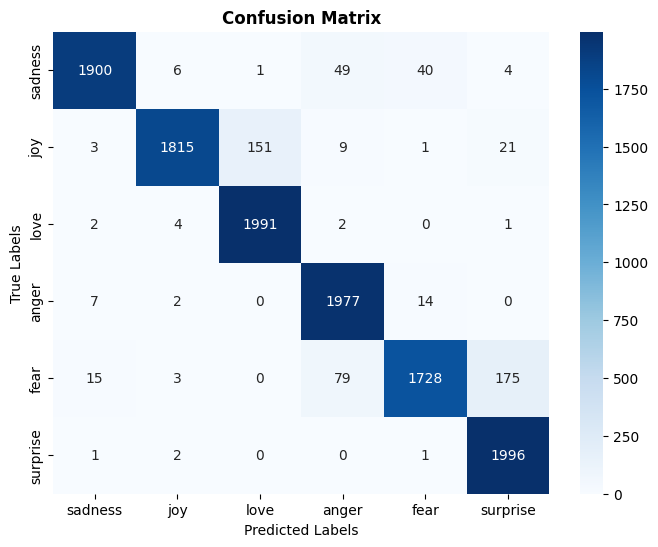

In [66]:
predictions,true_labels,_=trainer.predict(test_dataset)

predicted_labels=predictions.argmax(axis=1)

print('Classificaiton Report for BERT model :')
print(classification_report(true_labels,predicted_labels))

print('Confusion Matrix for BERT model')
cm = confusion_matrix(true_labels,predicted_labels)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, cmap='Blues', fmt='d', xticklabels=names, yticklabels=names)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix',fontweight='bold')
plt.show()


## Pushing to Hugging Face hub

In [ ]:
# from huggingface_hub import notebook_login
# notebook_login()

In [ ]:
# from huggingface_hub import whoami
# print(whoami())

In [ ]:
repo = "Deepakathf/bert-emotion-finetuned"
bert_model.push_to_hub(repo)        
bert_tokenizer.push_to_hub(repo)

In [68]:
repo="Deepakathf/bert-emotion-finetuned"

In [69]:
# Checking 
from transformers import pipeline

p = pipeline("text-classification", model=repo)
for text in ["i feel so happy today",
             "i can't believe this is happening, i'm terrified",
             "wow, i did not expect that at all"]:
    print(text, "->", p(text))

config.json:   0%|          | 0.00/1.06k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/351 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/712k [00:00<?, ?B/s]

i feel so happy today -> [{'label': 'joy', 'score': 0.999580442905426}]
i can't believe this is happening, i'm terrified -> [{'label': 'fear', 'score': 0.9994447827339172}]
wow, i did not expect that at all -> [{'label': 'surprise', 'score': 0.504184901714325}]


In [70]:
print('Finally done')

Finally done
